# Final Notebook 05 | Physics-Informed CHIRPS v3 RNL Calibration
**PH3043 · Six Sri Lankan stations · Development period 1981–1994**

**Research question H5:** Do ERA5 humidity and winds, and exploratory Copernicus terrain/orographic features, add *out-of-period* predictive value over raw CHIRPS v3 RNL and CHIRPS + seasonal features? **H6:** Can a model fitted to five stations transfer to a sixth held-out station? These are separate claims.

This notebook **does not extract new data**; it uses the previously processed merged daily file. Results from 1995–2000 are **not viewed or used**. All figures and tables are generated from this user's dataset. Read the explanations, run top-to-bottom, then answer the questions at the end.

**Caveats:** Reanalysis predictors are historical postprocessing inputs, *not an operational forecast*. Older terrain gradients are exploratory and may differ from subsequently corrected derivatives; this notebook makes **no causal orographic claim**. Six stations cannot support strong terrain generalization claims. For baseline comparisons, models use the **same station/date rows**.

## 0 · Setup and data provenance

Expected project structure:
```text
Sri Lanka Rain Fall Research/
├─ data/processed/Ground_CHIRPS_ERA5_Terrain_1981_2000.csv
├─ notebooks/Final_Notebooks/Final_05_Physics_Informed_CHIRPS_Validation.ipynb
├─ results/Final_05_Physics_Informed/
└─ scripts/   (previously executed CHIRPS, ERA5 and DEM GEE JavaScript)
```

The source filename may have `.csv` or `.xls` extension; some earlier `.xls` files contain **CSV-formatted text**. We detect the contents rather than assume an Excel workbook. The notebook searches upward for the project root, so it works when launched from `notebooks/Final_Notebooks`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from IPython.display import display

STATIONS=['Badulla','Colombo','Galle','Kandy','Nuwaraeliya','Puttalam']
FOLDS=[('1981-01-01','1986-12-31','1987-01-01','1988-12-31'),
       ('1981-01-01','1988-12-31','1989-01-01','1990-12-31'),
       ('1981-01-01','1990-12-31','1991-01-01','1992-12-31'),
       ('1981-01-01','1992-12-31','1993-01-01','1994-12-31')]

cwd=Path.cwd().resolve()
roots=[cwd,*cwd.parents,Path('/mnt/data')]
filenames=['Ground_CHIRPS_ERA5_Terrain_1981_2000.csv','Ground_CHIRPS_ERA5_Terrain_1981_2000.xls']
found=[]
for root in roots:
    for folder in [root/'data'/'processed',root]:
        for filename in filenames:
            path=folder/filename
            if path.is_file(): found.append((root,path))
if not found: raise FileNotFoundError('Merged CHIRPS + ERA5 + terrain data not found. Set DATA_PATH manually in the setup cell.')
ROOT,DATA_PATH=found[0]
if ROOT==Path('/mnt/data'): ROOT=Path('/mnt/data')
OUT_PARENT=ROOT/'results'/'Final_05_Physics_Informed'
num=1
while (OUT_PARENT/f'run_{num:03d}').exists():num+=1
OUT=OUT_PARENT/f'run_{num:03d}'
FIGDIR=OUT/'figures';TABDIR=OUT/'tables'
FIGDIR.mkdir(parents=True,exist_ok=False);TABDIR.mkdir(parents=True,exist_ok=False)
def save_fig(fig,name):
    fig.savefig(FIGDIR/(name+'.png'),dpi=240,bbox_inches='tight')
    fig.savefig(FIGDIR/(name+'.pdf'),bbox_inches='tight')
print('Source:',DATA_PATH,'\nOutput:',OUT)


Source: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed\Ground_CHIRPS_ERA5_Terrain_1981_2000.csv 
Output: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Final_05_Physics_Informed\run_001


## 1 · Load, verify, and audit features

**Why:** CHIRPS/gauge/date alignment must be checked *before* modelling. Humidity, wind and terrain columns come from your earlier GEE and Python workflow, not from new extraction. We exclude negative/missing values in required variables and report counts. The original source includes some derived gradients with ambiguous provenance; the terrain experiment is labelled exploratory.

In [2]:
data=pd.read_csv(DATA_PATH,parse_dates=['Date'],low_memory=False)
data['Station']=data.Station.astype(str).str.strip().replace({'Nuwara Eliya':'Nuwaraeliya'})
required=['Date','Station','Rainfall_mm','CHIRPS_V3_mm','CHIRPS_mm',
          'Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms',
          'Elevation_m','Slope_deg','dhdx','dhdy']
assert not (set(required)-set(data.columns)),f'Missing columns: {set(required)-set(data.columns)}'
assert not data.duplicated(['Date','Station']).any(),'Duplicate station/date keys'
assert set(data.Station.unique())==set(STATIONS)
for c in required[2:]:data[c]=pd.to_numeric(data[c],errors='coerce')
data=data[data.Date.between('1981-01-01','1994-12-31')].copy()
data['q_kgkg']=data['Specific_Humidity_gkg']/1000.0
# Local flow-over-slope PROXY; do not interpret as verified vertical velocity.
data['proxy_upslope_ms']=np.maximum(0,data.U10_ms*data.dhdx+data.V10_ms*data.dhdy)
data['proxy_moisture_upslope']=data.q_kgkg*data.proxy_upslope_ms
phase=2*np.pi*(data.Date.dt.dayofyear-1)/np.where(data.Date.dt.is_leap_year,366,365)
data['Sin1']=np.sin(phase);data['Cos1']=np.cos(phase)
data['Sin2']=np.sin(2*phase);data['Cos2']=np.cos(2*phase)
data['log1p_v3']=np.log1p(data.CHIRPS_V3_mm.clip(lower=0))
FEATURES={
 'Seasonal Ridge':['log1p_v3','Sin1','Cos1','Sin2','Cos2'],
 '+ Moisture':['log1p_v3','Sin1','Cos1','Sin2','Cos2','Specific_Humidity_gkg','RH_percent'],
 '+ Wind':['log1p_v3','Sin1','Cos1','Sin2','Cos2','Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms'],
 '+ Terrain proxy (exploratory)':['log1p_v3','Sin1','Cos1','Sin2','Cos2','Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms','Elevation_m','Slope_deg','dhdx','dhdy','proxy_upslope_ms','proxy_moisture_upslope']
}
model_columns=['Rainfall_mm','CHIRPS_V3_mm']+FEATURES['+ Terrain proxy (exploratory)']
qc=data.groupby('Station').agg(total_rows=('Date','size'),first=('Date','min'),last=('Date','max'))
valid=data.dropna(subset=model_columns).copy()
valid=valid.loc[(valid.Rainfall_mm>=0)&(valid.CHIRPS_V3_mm>=0)].sort_values(['Station','Date'])
qc['matched_feature_rows']=valid.groupby('Station').size()
qc['rows_excluded']=qc.total_rows-qc.matched_feature_rows
print('All models use the same finite-feature station/date observations.')
display(qc)
qc.to_csv(TABDIR/'01_feature_coverage.csv')
assert (valid.Date<'1995-01-01').all()


All models use the same finite-feature station/date observations.


,total_rows,first,last,matched_feature_rows,rows_excluded
Station,,,,,
Badulla,5109,1981-01-01,1994-12-31,5109,0
Colombo,5088,1981-01-01,1994-12-31,5088,0
Galle,5099,1981-01-01,1994-12-31,5099,0
Kandy,5106,1981-01-01,1994-12-31,5106,0
Nuwaraeliya,5098,1981-01-01,1994-12-31,5098,0
Puttalam,5103,1981-01-01,1994-12-31,5103,0



## 2 · Physical Motivation and Model Definitions

**A (Baseline):** Raw \(S_d\) from CHIRPS v3 RNL.

**B:** Seasonal Ridge regression with \(\log(1+S_d)\) and annual/semiannual Fourier harmonics.

**C:** Model B plus ERA5 specific humidity (g/kg) and relative humidity (%).

**D:** Model C plus ERA5 wind components \(u_{10}\), \(v_{10}\), and wind speed (m/s).

**E:** Model D plus elevation, slope, finite-difference terrain gradients, and an *exploratory* moisture-weighted upslope proxy.

### Modelling Equation

The rainfall prediction model is defined as:

$$
\hat{G}_d = \max\left\{0,\beta_0 + \mathbf{x}_d^\top\boldsymbol{\beta}\right\}
$$

The Ridge regression coefficients are estimated by minimizing:

$$
\hat{\boldsymbol{\beta}}
=
\underset{\beta_0,\boldsymbol{\beta}}{\arg\min}
\left[
\sum_{d\in\mathrm{train}}
\left(
G_d-\beta_0-\mathbf{x}_d^\top\boldsymbol{\beta}
\right)^2
+
\alpha\|\boldsymbol{\beta}\|_2^2
\right]
$$

where:

- \(G_d\) = Gauge-observed daily rainfall
- \(\hat{G}_d\) = Predicted daily rainfall
- \(\mathbf{x}_d\) = Feature vector for day \(d\)
- \(\beta_0\) = Intercept
- \(\boldsymbol{\beta}\) = Ridge regression coefficients
- \(\alpha\) = Regularization strength

### Feature Standardization and Model Comparison

Features are standardized **inside the training-fold pipeline**.

All models use a fixed regularization parameter:

$$
\alpha = 10
$$

This avoids introducing hyperparameter search bias into the comparison.

Feature groups are **nested**, allowing the incremental predictive contribution of each group to be evaluated:

- **C vs B:** An improvement in Model C over Model B supports the incremental predictive value of atmospheric moisture.
- **D vs C:** An improvement in Model D over Model C supports the incremental predictive value of wind variables.
- **E vs D:** An improvement in Model E over Model D explores the additional predictive value of terrain-related proxies.

**Important:** Improvements in predictive performance should not be interpreted as proof of physical causation.

### Exploratory Upslope Proxy

The local upslope proxy is defined as:

$$
w^* =
\max\left(
0,\,
u_{10}\frac{\partial h}{\partial x}
+
v_{10}\frac{\partial h}{\partial y}
\right)
$$

where:

- \(w^*\) = Simplified upslope-flow diagnostic
- \(u_{10}\) = Eastward wind component at 10 m (m/s)
- \(v_{10}\) = Northward wind component at 10 m (m/s)
- \(h\) = Terrain elevation (m)
- \(\frac{\partial h}{\partial x}\) = Terrain gradient in the east–west direction
- \(\frac{\partial h}{\partial y}\) = Terrain gradient in the north–south direction

The proxy \(w^*\) is a **simplified diagnostic**, not the vertical velocity of a dynamically resolved orographic airflow.

In particular, **10 m wind measurements are not necessarily representative of free-atmosphere winds responsible for orographic lifting**.


## 3 · Functions: scores and scientific plots

Every metric uses matched observations. Bias = prediction − gauge; RMSE and MAE in mm/day. Wet day ≥1 mm/day; heavy observed day ≥25 mm/day. Heavy-event RMSE is conditional on observed heavy days and is *not* an event-detection score.

In [14]:
def scores(gauge,est):
    y=np.asarray(gauge,float);p=np.asarray(est,float)
    ok=np.isfinite(y)&np.isfinite(p);y=y[ok];p=p[ok]
    if len(y)==0:return {'n':0,'RMSE':np.nan,'MAE':np.nan,'Bias':np.nan,'Pearson_r':np.nan}
    e=p-y
    r=np.corrcoef(y,p)[0,1] if len(y)>1 and np.std(y)>0 and np.std(p)>0 else np.nan
    return {'n':len(y),'RMSE':np.sqrt(np.mean(e**2)),'MAE':np.mean(abs(e)),'Bias':e.mean(),'Pearson_r':r}

def occurrence(gauge,est):
    y=np.asarray(gauge,float)>=1;p=np.asarray(est,float)>=1
    H=int((y&p).sum());M=int((y&~p).sum());F=int((~y&p).sum())
    safe=lambda a,b: a/b if b else np.nan
    return {'hits':H,'misses':M,'false_alarms':F,'POD':safe(H,H+M),'FAR':safe(F,H+F),'CSI':safe(H,H+M+F)}

def plot_delta_dot(scores_df,reference='Raw v3',title='Model comparison',save_as=None):
    d=scores_df[scores_df.Model!=reference].copy()
    pivot=d.pivot(index='Station',columns='Model',values='Improvement_percent').reindex(STATIONS)
    fig,ax=plt.subplots(figsize=(10,5.5));ys=np.arange(len(STATIONS))
    for k,col in enumerate(pivot.columns):ax.scatter(pivot[col],ys+(k-(len(pivot.columns)-1)/2)*.13,label=col,s=55)
    ax.axvline(0,c='black',lw=1,ls='--');ax.set_yticks(ys,STATIONS);ax.invert_yaxis()
    ax.set_xlabel('Daily RMSE reduction vs raw CHIRPS v3 RNL (%)');ax.set_title(title);ax.legend(fontsize=8,loc='best');ax.grid(axis='x',alpha=.2);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

def plot_ablation_heatmap(scores_df,metric='RMSE',save_as=None):
    a=scores_df.pivot(index='Station',columns='Model',values=metric).reindex(index=STATIONS,columns=['Raw v3']+list(FEATURES))
    fig,ax=plt.subplots(figsize=(11,5));values=a.to_numpy(float)
    im=ax.imshow(values,aspect='auto',cmap='viridis');ax.set_xticks(np.arange(len(a.columns)),a.columns,rotation=28,ha='right');ax.set_yticks(np.arange(len(a.index)),a.index)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):ax.text(j,i,f'{values[i,j]:.2f}',ha='center',va='center',color='white',fontsize=8,bbox=dict(facecolor='black',alpha=.25,edgecolor='none'))
    fig.colorbar(im,ax=ax,label='RMSE (mm/day)' if metric=='RMSE' else metric);ax.set_title('Out-of-fold model ablation — '+metric);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

def plot_scatter_predictions(pred,station='Kandy',method='+ Moisture',save_as=None):
    d=pred[(pred.Station==station)&(pred.Model.isin(['Raw v3',method]))]
    fig,axs=plt.subplots(1,2,figsize=(11,4),sharex=True,sharey=True)
    for ax,(name,g) in zip(axs,d.groupby('Model',sort=False)):
        ax.scatter(g.Gauge_mm_day,g.Prediction_mm_day,s=6,alpha=.25);lim=max(g.Gauge_mm_day.max(),g.Prediction_mm_day.max());ax.plot([0,lim],[0,lim],'k--',lw=1);ax.set_title(name);ax.set_xlabel('Gauge (mm/day)');ax.set_ylabel('Estimate (mm/day)')
    fig.suptitle(station+' — paired out-of-fold daily rainfall');fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,axs


## 4 · Main H5: station-specific, expanding-window feature ablation

**Why rolling-origin?** Each fit only sees earlier years. This directly examines improvement in later years while avoiding random split leakage. Each station's models are fitted *only* on that station's own historical values. For fair comparisons, model groups share eligible dates. We keep the **same four folds as Notebooks 03–04**. Fixed \(lpha=10\) is a predeclared example, not a data-optimized optimum.

In [16]:
pred_rows=[];fold_rows=[]
for station in STATIONS:
    s=valid[valid.Station==station]
    for fold,(ts,te,vs,ve) in enumerate(FOLDS,1):
        tr=s[s.Date.between(ts,te)];va=s[s.Date.between(vs,ve)]
        assert tr.Date.max()<va.Date.min()
        for method in ['Raw v3']+list(FEATURES):
            if method=='Raw v3':p=va.CHIRPS_V3_mm.to_numpy(float)
            else:
                pipe=make_pipeline(StandardScaler(),Ridge(alpha=10))
                pipe.fit(tr[FEATURES[method]],tr.Rainfall_mm)
                p=np.maximum(0,pipe.predict(va[FEATURES[method]]))
            tmp=pd.DataFrame({'Date':va.Date.values,'Station':station,'fold':fold,'Model':method,
                              'Gauge_mm_day':va.Rainfall_mm.values,'Prediction_mm_day':p})
            pred_rows.append(tmp)
            fold_rows.append({'Station':station,'fold':fold,'Model':method,**scores(va.Rainfall_mm,p),**occurrence(va.Rainfall_mm,p)})
predictions=pd.concat(pred_rows,ignore_index=True)
fold_scores=pd.DataFrame(fold_rows)
assert predictions.Date.max()<pd.Timestamp('1995-01-01')
assert not predictions.duplicated(['Date','Station','Model']).any()
print('Distinct validation station-days:',len(predictions[predictions.Model=='Raw v3']))
display(fold_scores.head(12).round(3))
predictions.to_csv(TABDIR/'02_rolling_validation_predictions.csv',index=False)
fold_scores.to_csv(TABDIR/'03_fold_scores.csv',index=False)


Distinct validation station-days: 17476


,Station,fold,Model,n,RMSE,MAE,Bias,Pearson_r,hits,misses,false_alarms,POD,FAR,CSI
0,Badulla,1,Raw v3,729,11.051,5.613,0.446,0.261,210,57,194,0.787,0.480,0.456
1,Badulla,1,Seasonal Ridge,729,10.073,5.787,1.057,0.317,243,24,291,0.910,0.545,0.435
2,Badulla,1,+ Moisture,729,9.998,5.775,1.156,0.333,247,20,301,0.925,0.549,0.435
3,Badulla,1,+ Wind,729,9.961,5.820,1.258,0.341,250,17,319,0.936,0.561,0.427
4,Badulla,1,+ Terrain proxy (exploratory),729,9.966,5.808,1.241,0.339,252,15,312,0.944,0.553,0.435
5,Badulla,2,Raw v3,728,12.363,5.624,-0.173,0.497,186,68,185,0.732,0.499,0.424
6,Badulla,2,Seasonal Ridge,728,12.725,5.804,-0.238,0.391,233,21,289,0.917,0.554,0.429
7,Badulla,2,+ Moisture,728,12.672,5.656,-0.386,0.405,235,19,285,0.925,0.548,0.436
8,Badulla,2,+ Wind,728,12.596,5.570,-0.356,0.419,236,18,272,0.929,0.535,0.449
9,Badulla,2,+ Terrain proxy (exploratory),728,12.589,5.567,-0.343,0.420,233,21,273,0.917,0.540,0.442


## 5 · H5 results: compare daily errors, wet days and heavy-rainfall trade-offs

A smaller RMSE is helpful, but cannot guarantee improvements in wet-day detection, extremes or monthly totals. Nested feature addition may *worsen* out-of-fold predictions; report that openly. This comparison is **development-period exploratory** and does not establish final station winners.

,Station,Model,n,RMSE,MAE,Bias,Pearson_r,hits,misses,false_alarms,POD,FAR,CSI,Heavy_n,Heavy_RMSE,Improvement_percent
1,Badulla,+ Terrain proxy (exploratory),2918,10.677,5.438,0.436,0.408,932,76,1085,0.925,0.538,0.445,163,38.704,5.357
2,Badulla,+ Wind,2918,10.682,5.448,0.439,0.407,933,75,1098,0.926,0.541,0.443,163,38.730,5.314
0,Badulla,+ Moisture,2918,10.737,5.465,0.373,0.396,928,80,1097,0.921,0.542,0.441,163,38.935,4.820
4,Badulla,Seasonal Ridge,2918,10.801,5.564,0.420,0.385,919,89,1105,0.912,0.546,0.435,163,38.876,4.250
3,Badulla,Raw v3,2918,11.281,5.430,0.229,0.413,801,207,727,0.795,0.476,0.462,163,35.982,0.000
8,Colombo,Raw v3,2897,16.162,6.786,-0.467,0.453,961,123,881,0.887,0.478,0.489,219,52.553,0.000
6,Colombo,+ Terrain proxy (exploratory),2897,16.569,6.974,-0.615,0.416,995,89,1064,0.918,0.517,0.463,219,56.402,-2.523
7,Colombo,+ Wind,2897,16.584,7.000,-0.594,0.413,998,86,1068,0.921,0.517,0.464,219,56.419,-2.612
5,Colombo,+ Moisture,2897,16.602,7.002,-0.640,0.411,994,90,1028,0.917,0.508,0.471,219,56.481,-2.722
9,Colombo,Seasonal Ridge,2897,16.740,7.156,-0.620,0.391,982,102,1007,0.906,0.506,0.470,219,56.876,-3.579


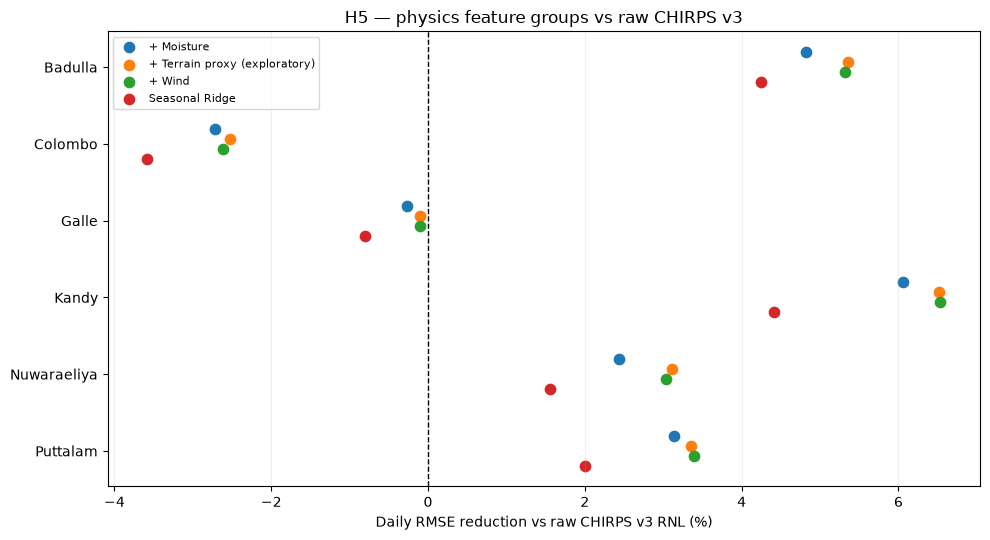

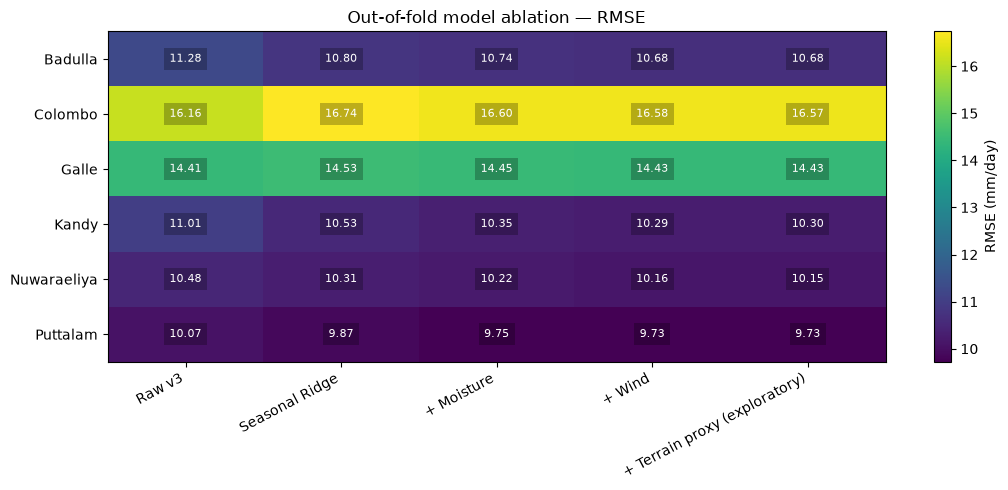

In [18]:
rows=[]
for (station,model),d in predictions.groupby(['Station','Model']):
    y=d.Gauge_mm_day.to_numpy();p=d.Prediction_mm_day.to_numpy()
    heavy=y>=25
    rows.append({'Station':station,'Model':model,**scores(y,p),**occurrence(y,p),
                 'Heavy_n':int(heavy.sum()),'Heavy_RMSE':scores(y[heavy],p[heavy])['RMSE']})
model_scores=pd.DataFrame(rows)
raw_reference=model_scores[model_scores.Model=='Raw v3'].set_index('Station').RMSE
model_scores['Improvement_percent']=model_scores.apply(lambda r:100*(raw_reference.loc[r.Station]-r.RMSE)/raw_reference.loc[r.Station],axis=1)
model_scores=model_scores.sort_values(['Station','RMSE'])
display(model_scores.round(3))
model_scores.to_csv(TABDIR/'04_station_feature_ablation.csv',index=False)
fig,ax=plot_delta_dot(model_scores,title='H5 — physics feature groups vs raw CHIRPS v3',save_as='01_ablation_percent_dot');plt.show()
fig,ax=plot_ablation_heatmap(model_scores,save_as='02_ablation_rmse_heatmap');plt.show()


## 6 · Correlation matrices: descriptive physics diagnostics

Correlation does **not** show causation. Shared seasonality may produce correlations without incremental predictive value. Use **Spearman** to assess monotonic association and **Pearson** for linear association; many variables (RH, humidity, temperature, wind components) can be collinear. We display selected variables from **1981–1994 only**. For genuine independence in spatial analysis, remember that terrain quantities repeat each day at the same station: six stations do not become thousands of independent terrain replicates.

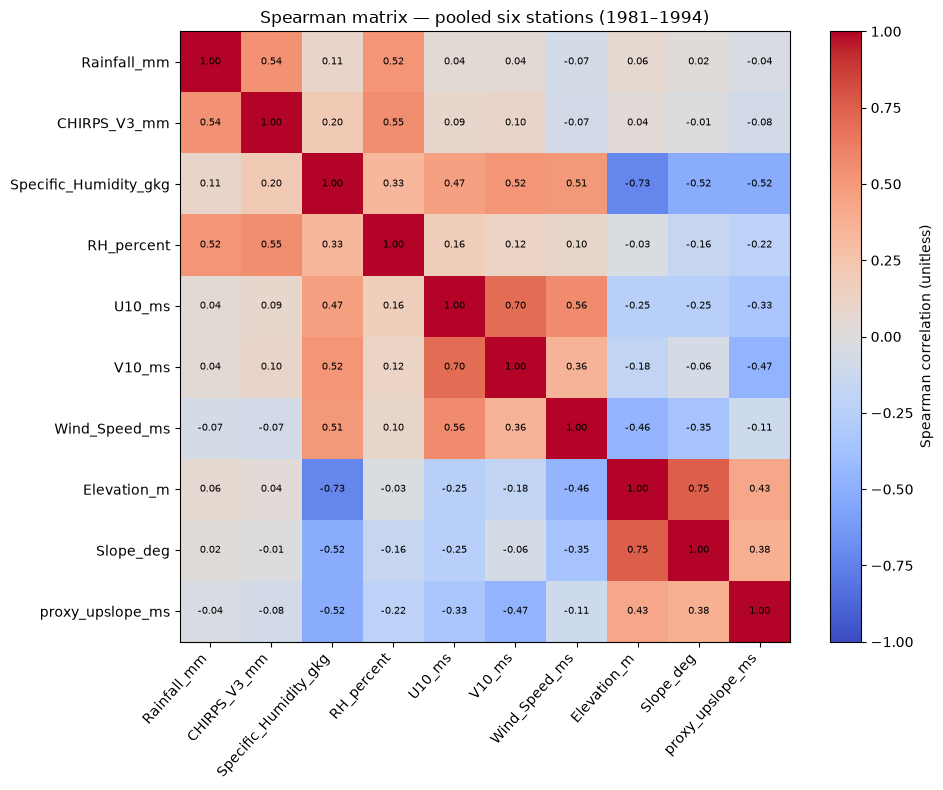

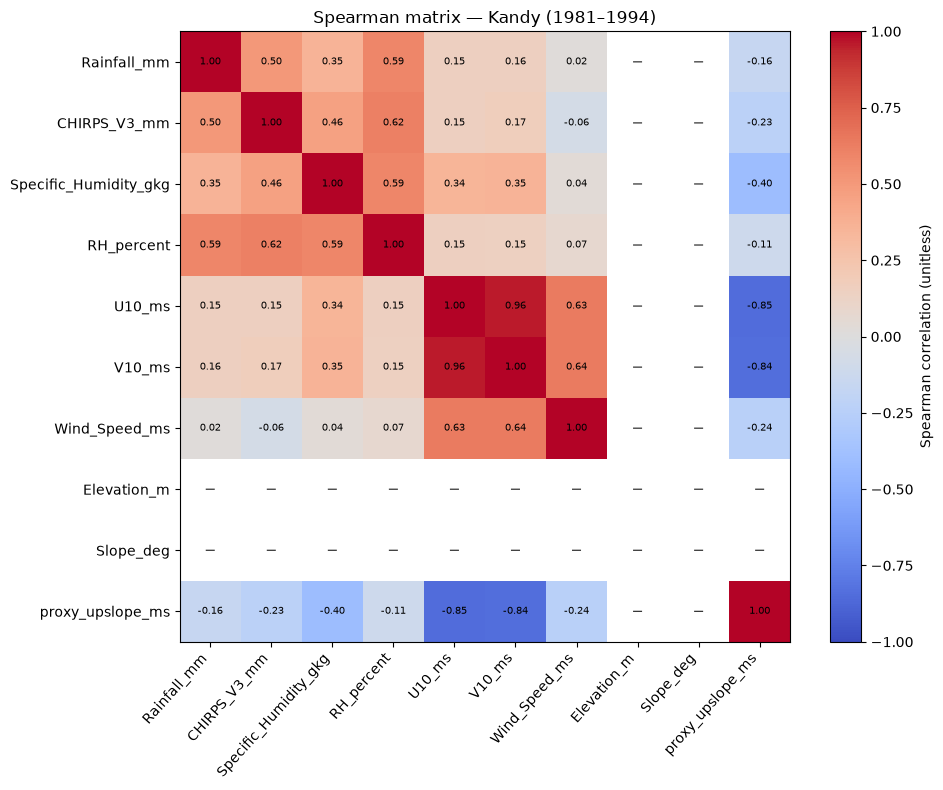

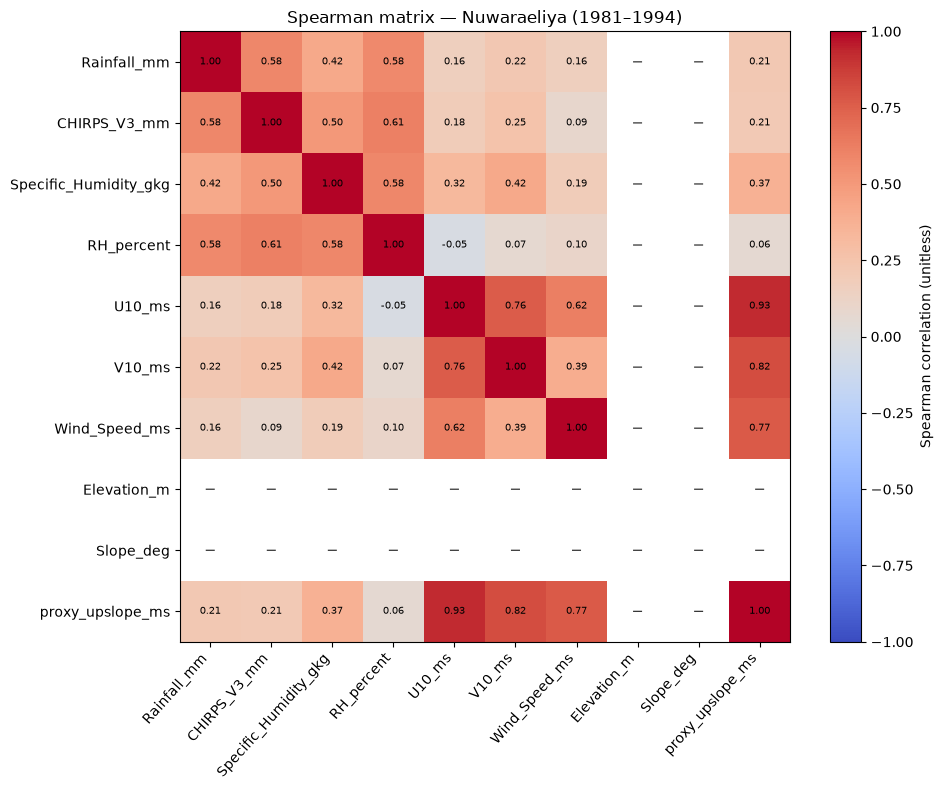

In [11]:
CORR_COLS=['Rainfall_mm','CHIRPS_V3_mm','Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms','Elevation_m','Slope_deg','proxy_upslope_ms']
def plot_correlation_matrix(frame,method='spearman',station=None,save_as=None):
    s=frame if station is None else frame[frame.Station==station]
    c=s[CORR_COLS].corr(method=method)
    fig,ax=plt.subplots(figsize=(10,8));im=ax.imshow(c,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(c.columns)),c.columns,rotation=48,ha='right');ax.set_yticks(range(len(c.index)),c.index)
    for i in range(len(c)):
        for j in range(len(c)):
            v=c.iloc[i,j];ax.text(j,i,f'{v:.2f}' if np.isfinite(v) else '—',ha='center',va='center',fontsize=7)
    fig.colorbar(im,ax=ax,label=f'{method.capitalize()} correlation (unitless)');ax.set_title(f'{method.capitalize()} matrix — {station or "pooled six stations"} (1981–1994)');fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax,c
for station in [None,'Kandy','Nuwaraeliya']:
    tag=station or 'pooled';fig,ax,matrix=plot_correlation_matrix(valid,station=station,save_as='03_spearman_'+tag);plt.show()
    matrix.to_csv(TABDIR/f'05_spearman_{tag}.csv')


## 7 · H6: leave-one-station-out (LOSO), with time held out too

**Different research question:** Can a *shared* physics model trained on **five other stations in 1981–1990** predict the sixth station in **1991–1994**? We never use the held-out station's gauge targets for fitting or threshold selection, and never use future dates as training. This is a more demanding assessment than station-specific calibration.

We compare raw v3 with shared Ridge models using seasonal, moisture/wind, and exploratory terrain features. The training sample has only **five distinct training locations** for terrain; consequently, do not claim a spatially generalizable terrain law. Some fields can encode station identity, leading to poor extrapolation; record failures. For strict leave-one-station-out, do not use the held-out station's gauge measurements for preprocessing.

In [20]:
LOSO_FOLDS=[('1981-01-01','1990-12-31','1991-01-01','1994-12-31')]
lo_rows=[];lo_preds=[]
for held in STATIONS:
    train=valid[(valid.Station!=held)&valid.Date.between('1981-01-01','1990-12-31')]
    evaluation=valid[(valid.Station==held)&valid.Date.between('1991-01-01','1994-12-31')]
    assert held not in set(train.Station)
    assert train.Date.max()<evaluation.Date.min()
    for method in ['Raw v3']+list(FEATURES):
        if method=='Raw v3':p=evaluation.CHIRPS_V3_mm.to_numpy(float)
        else:
            pipeline=make_pipeline(StandardScaler(),Ridge(alpha=10))
            pipeline.fit(train[FEATURES[method]],train.Rainfall_mm)
            p=np.maximum(0,pipeline.predict(evaluation[FEATURES[method]]))
        lo_rows.append({'Held_out_station':held,'Model':method,**scores(evaluation.Rainfall_mm,p),**occurrence(evaluation.Rainfall_mm,p)})
        lo_preds.append(pd.DataFrame({'Date':evaluation.Date.values,'Held_out_station':held,'Model':method,
                                     'Gauge_mm_day':evaluation.Rainfall_mm.values,'Prediction_mm_day':p}))
loso_scores=pd.DataFrame(lo_rows)
loso_predictions=pd.concat(lo_preds,ignore_index=True)
ref=loso_scores[loso_scores.Model=='Raw v3'].set_index('Held_out_station').RMSE
loso_scores['RMSE_improvement_percent']=loso_scores.apply(lambda r:100*(ref.loc[r.Held_out_station]-r.RMSE)/ref.loc[r.Held_out_station],axis=1)
display(loso_scores.round(3))
loso_scores.to_csv(TABDIR/'06_LOSO_scores.csv',index=False)
loso_predictions.to_csv(TABDIR/'07_LOSO_predictions.csv',index=False)


,Held_out_station,Model,n,RMSE,MAE,Bias,Pearson_r,hits,misses,false_alarms,POD,FAR,CSI,RMSE_improvement_percent
0,Badulla,Raw v3,1461,10.820,5.243,0.320,0.413,405,82,348,0.832,0.462,0.485,0.000
1,Badulla,Seasonal Ridge,1461,10.127,5.231,0.255,0.417,425,62,429,0.873,0.502,0.464,6.400
2,Badulla,+ Moisture,1461,9.975,4.928,0.017,0.444,428,59,381,0.879,0.471,0.493,7.813
3,Badulla,+ Wind,1461,9.979,4.931,0.011,0.444,429,58,381,0.881,0.470,0.494,7.775
4,Badulla,+ Terrain proxy (exploratory),1461,10.842,4.081,-3.303,0.427,269,218,91,0.552,0.253,0.465,-0.204
5,Colombo,Raw v3,1460,17.957,6.729,-0.503,0.461,489,61,442,0.889,0.475,0.493,0.000
6,Colombo,Seasonal Ridge,1460,18.899,7.223,-0.929,0.385,507,43,534,0.922,0.513,0.468,-5.241
7,Colombo,+ Moisture,1460,18.907,7.148,-1.054,0.389,512,38,538,0.931,0.512,0.471,-5.286
8,Colombo,+ Wind,1460,18.935,7.203,-1.014,0.385,520,30,554,0.945,0.516,0.471,-5.445
9,Colombo,+ Terrain proxy (exploratory),1460,18.859,7.195,-0.879,0.394,517,33,565,0.940,0.522,0.464,-5.019


## 8 · Reusable LOSO plot and station-specific skill map

**Visual question:** Do the added features help when the target station is unseen, or do they only fit patterns at known stations? Negative improvements are scientifically important.

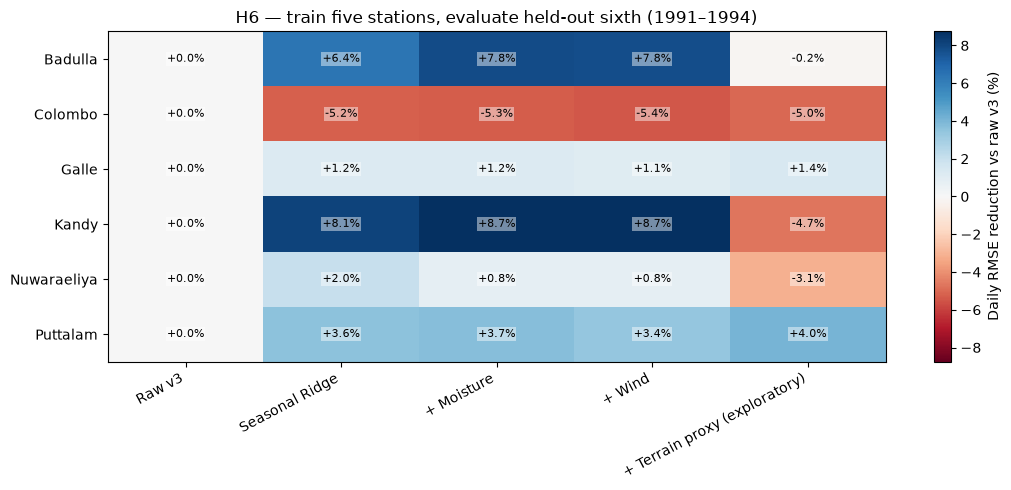

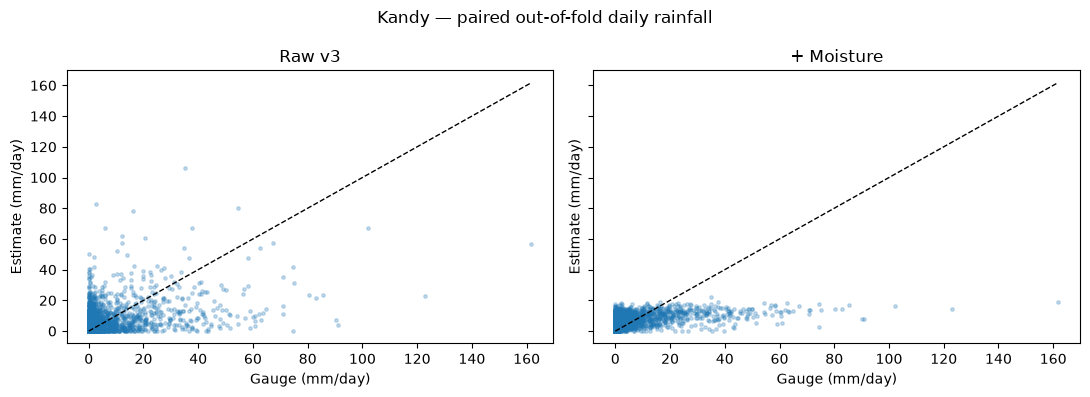

In [22]:
def plot_loso_heatmap(scores,save_as=None):
    d=scores.pivot(index='Held_out_station',columns='Model',values='RMSE_improvement_percent').reindex(index=STATIONS,columns=['Raw v3']+list(FEATURES))
    a=d.to_numpy(float);limit=max(5,float(np.nanmax(abs(a))))
    fig,ax=plt.subplots(figsize=(11,5));im=ax.imshow(a,vmin=-limit,vmax=limit,cmap='RdBu',aspect='auto')
    ax.set_xticks(range(len(d.columns)),d.columns,rotation=28,ha='right');ax.set_yticks(range(len(d.index)),d.index)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):ax.text(j,i,f'{a[i,j]:+.1f}%',ha='center',va='center',fontsize=8,color='black',bbox=dict(facecolor='white',alpha=.45,edgecolor='none',pad=1))
    fig.colorbar(im,ax=ax,label='Daily RMSE reduction vs raw v3 (%)');ax.set_title('H6 — train five stations, evaluate held-out sixth (1991–1994)');fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax
fig,ax=plot_loso_heatmap(loso_scores,save_as='04_LOSO_skill_heatmap');plt.show()
fig,axs=plot_scatter_predictions(predictions,station='Kandy',method='+ Moisture',save_as='05_Kandy_moisture_scatter');plt.show()


## 9 · Temporal stability: plot 4-fold RMSE changes for each feature group

We do not use the historical test to choose a candidate. A model with a positive average improvement but large negative folds is less convincing than one with gains in all folds. The fold-heatmap evaluates **station-specific** models, not LOSO.

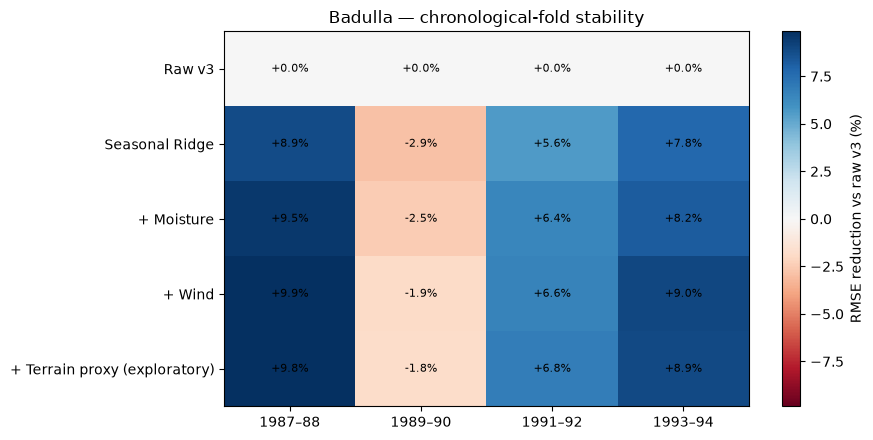

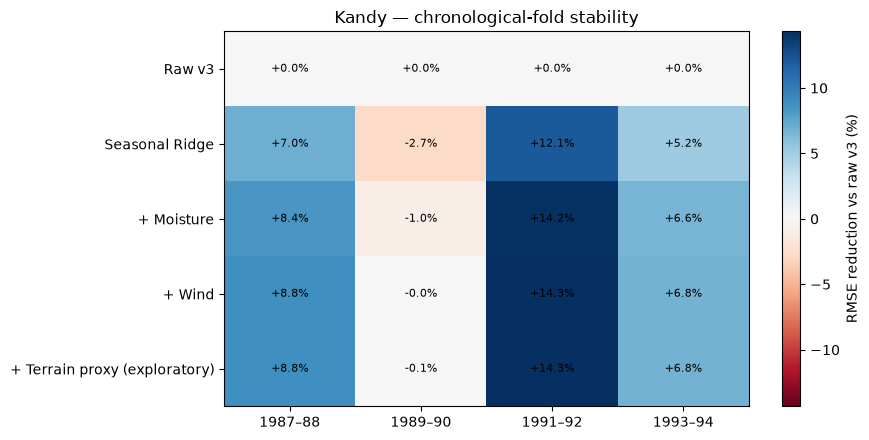

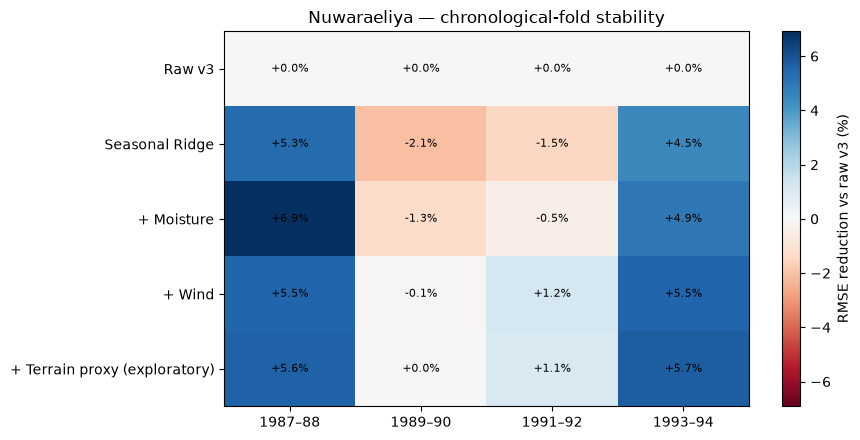

In [24]:
def plot_fold_skill_heatmap(fold_scores,station='Kandy',save_as=None):
    d=fold_scores[fold_scores.Station==station].copy();r=d[d.Model=='Raw v3'].set_index('fold').RMSE
    d['skill']=d.apply(lambda x:100*(r.loc[x.fold]-x.RMSE)/r.loc[x.fold],axis=1)
    a=d.pivot(index='Model',columns='fold',values='skill').reindex(index=['Raw v3']+list(FEATURES),columns=[1,2,3,4]);values=a.to_numpy(float)
    lim=max(1,float(np.nanmax(abs(values))));fig,ax=plt.subplots(figsize=(9,4.5));im=ax.imshow(values,cmap='RdBu',vmin=-lim,vmax=lim,aspect='auto')
    ax.set_yticks(range(len(a.index)),a.index);ax.set_xticks(range(4),['1987–88','1989–90','1991–92','1993–94'])
    for i in range(len(a)):
        for j in range(4):ax.text(j,i,f'{values[i,j]:+.1f}%',ha='center',va='center',fontsize=8)
    fig.colorbar(im,ax=ax,label='RMSE reduction vs raw v3 (%)');ax.set_title(station+' — chronological-fold stability');fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax
for station in ['Badulla','Kandy','Nuwaraeliya']:
    fig,ax=plot_fold_skill_heatmap(fold_scores,station,save_as='06_fold_stability_'+station);plt.show()


## 10 · Scientific evidence table and interpretation checklist

These rows are **comparative evidence**, not automatically a station-specific selection. Our final Notebook 06 will apply the agreed multi-metric decision rule, compare daily/accumulated performance, and report historical evaluation.

- **H5:** Does adding moisture to seasonal CHIRPS lower RMSE consistently? Does wind add beyond moisture? Does terrain provide incremental gain beyond moisture/wind? Can the apparent gains be explained by confounding with seasonality or station characteristics?
- **H6:** Does a model learned from other stations improve when the station's gauge was held out completely? Where does it fail? Why might point-versus-grid mismatch and six-station terrain sample size limit transfer?
- **Wet days:** Did CSI, POD and FAR improve or deteriorate? Does the model mistakenly predict rain on dry days?
- **Heavy rainfall:** Are errors on gauge-defined ≥25 mm/day events reduced, or are extremes compressed?
- **Residual dependence:** We are not claiming independent daily errors; chronological folds address one leakage mode but do not make samples independent.
- **Provenance:** These exploratory orographic features depend on earlier finite differences and 10 m ERA5 winds. Document their GEE script settings and verify terrain calculation methods before asserting physical lifting or use in final conclusions.

**Recommended final wording after execution:** “Feature-group ablation under rolling-origin validation showed [insert observed station-specific RMSE results]. Physics-informed variables [did/did not] improve the baseline consistently, while [insert wet-day/extreme results]. Leave-one-station-out transfer was [insert observations], demonstrating [limits]. These are associations and predictive comparisons, not causal evidence of orographic rainfall enhancement.”

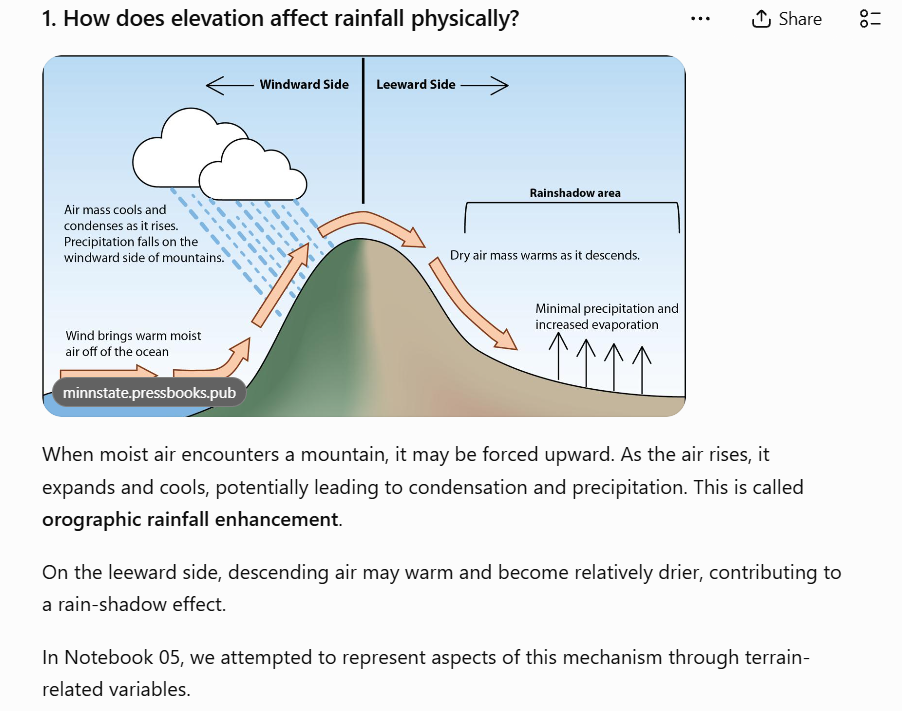

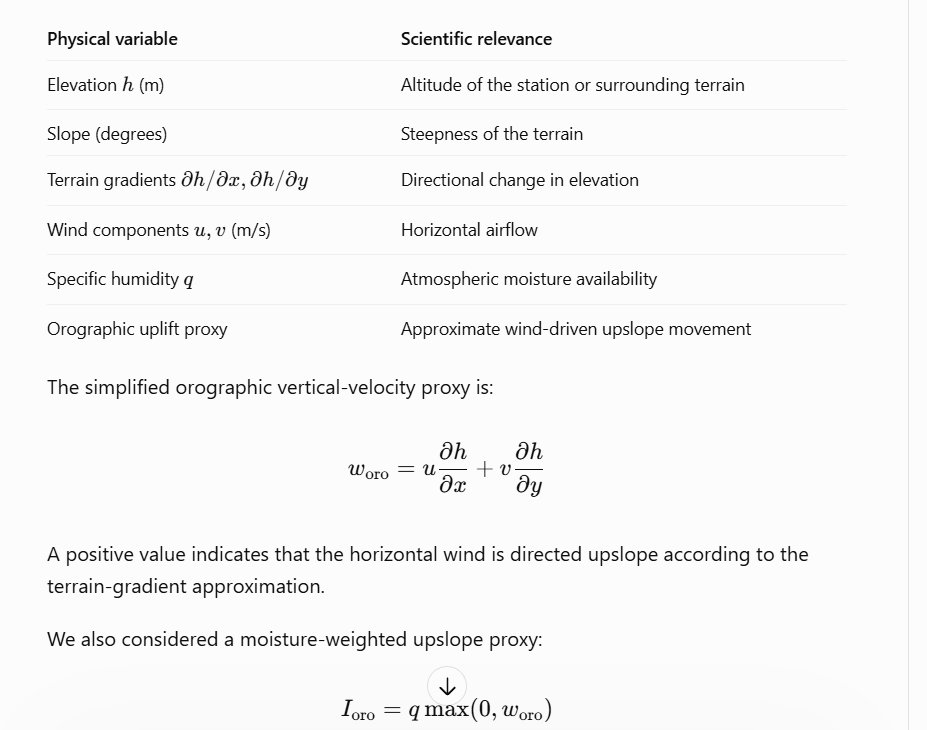

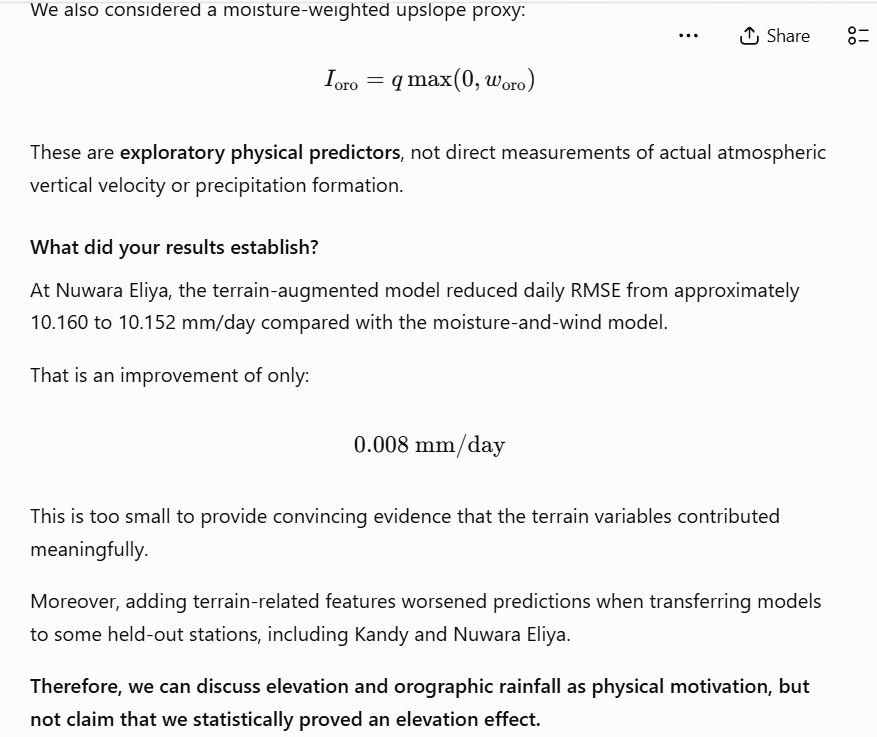

## 11 · Accessible literature and dataset references

1. Funk, C. et al. (2015), *The climate hazards infrared precipitation with stations—A new environmental record for monitoring extremes*. **Scientific Data** 2, 150066. https://doi.org/10.1038/sdata.2015.66
2. Funk, C. et al. (2026), *The Climate Hazards Center Infrared Precipitation with Stations, Version 3*. **Scientific Data** 13, 718. https://doi.org/10.1038/s41597-026-07096-4
3. Hersbach, H. et al. (2020), *The ERA5 global reanalysis*. **Quarterly Journal of the Royal Meteorological Society** 146, 1999–2049. https://doi.org/10.1002/qj.3803
4. ECMWF/Copernicus Climate Data Store, ERA5 single levels: https://doi.org/10.24381/cds.adbb2d47
5. Copernicus DEM GLO-30 source catalogue: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30
6. scikit-learn, Ridge regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

**Original figures in this notebook are computed from the user’s processed datasets.** If you reuse a diagram from a paper, explicitly cite that source in its caption. This notebook includes no copied external figures.

**Suggested GitHub README inputs:** `data/processed/Ground_CHIRPS_ERA5_Terrain_1981_2000.csv`, prior GEE scripts and processing notebooks; outputs in `results/Final_05_Physics_Informed/run_###/`. Include station coordinates, aggregation conventions and units when documenting reproducibility.

## Final Scientific Conclusion — Notebook 05

This study investigated whether physically motivated atmospheric and topographic variables improve CHIRPS v3 RNL daily rainfall estimation at six meteorological stations in Sri Lanka. Five model configurations were evaluated, progressing from uncorrected CHIRPS v3 RNL to seasonal Ridge regression and incorporating ERA5 atmospheric moisture, wind, and Copernicus terrain-derived predictors. Model performance was assessed using four expanding-window validation folds covering 1987–1994, followed by an exploratory leave-one-station-out spatial generalization experiment.

### Contribution of Atmospheric Variables

The addition of atmospheric moisture and wind predictors improved daily rainfall RMSE at selected stations. The greatest reduction was observed at Kandy, where the moisture-and-wind model decreased RMSE from 11.014 to 10.294 mm/day, corresponding to an improvement of 6.53% relative to raw CHIRPS v3 RNL. Improvements were also observed at Badulla, Nuwara Eliya, and Puttalam, while raw CHIRPS v3 RNL remained the lowest-RMSE candidate at Colombo and Galle.

These findings suggest that atmospheric humidity and wind contain useful predictive information beyond CHIRPS precipitation estimates and seasonal harmonics at certain locations. However, the improvements were not universal and did not consistently extend to wet-day detection or heavy-rainfall estimation.

### Contribution of Elevation and Orographic Effects

Topographic characteristics influence atmospheric flow and precipitation formation, particularly in mountainous environments. To investigate their potential contribution, elevation, slope, terrain gradients, and exploratory moisture-weighted upslope-flow proxies were incorporated into the calibration models.

The terrain-augmented models produced negligible additional improvements beyond the atmospheric moisture-and-wind models. For example, at Nuwara Eliya, adding terrain-related predictors reduced daily RMSE by only 0.008 mm/day relative to the wind-augmented model.

Furthermore, the terrain-augmented model demonstrated poor spatial transfer at selected stations. In the leave-one-station-out experiment, adding terrain variables changed Kandy's RMSE improvement from +8.75% with moisture and wind to −4.70% relative to raw CHIRPS v3 RNL.

These results do not establish that elevation or orographic processes are unimportant for rainfall in Sri Lanka. Rather, they indicate that the simplified terrain representation employed in this investigation did not provide a consistently useful additional correction.

Because only six station locations were considered, and several terrain predictors were effectively constant within each station, the analysis could not independently isolate the influence of elevation from other location-specific climatic characteristics.

### Spatial Generalization

Leave-one-station-out validation demonstrated that some atmospheric calibration relationships could transfer to previously excluded stations. Improvements were observed at Badulla and Kandy, with smaller benefits at several other stations. However, all tested correction models worsened RMSE at Colombo.

These findings suggest that the transferability of physics-informed rainfall corrections is geographically dependent. A single calibration model cannot be assumed to perform equally well across coastal, lowland, and mountainous environments.

### Overall Conclusion

**Hypothesis H5 is partially supported:** Atmospheric moisture and wind improve daily rainfall RMSE at selected stations, but the addition of exploratory terrain features does not provide consistent independent predictive benefit.

**Hypothesis H6 is partially supported:** Simpler atmospheric calibration models demonstrate useful spatial transfer at selected stations, but performance is inconsistent across the six held-out locations, particularly when terrain-related predictors are introduced.

Overall, the investigation demonstrates that physically motivated predictors can improve CHIRPS v3 RNL rainfall estimation under certain conditions, but increasing model complexity does not necessarily lead to better predictive performance.

The results also highlight an important distinction between statistical improvement and physical interpretation. Although elevation, terrain gradients, atmospheric moisture, and wind are relevant to orographic rainfall processes, the present numerical experiments do not demonstrate a causal relationship between these variables and the observed model improvements.

The most defensible approach is therefore to select correction models separately for each station using chronological validation, retain uncorrected CHIRPS when additional predictors offer negligible benefits, and evaluate multiple rainfall characteristics rather than relying exclusively on daily RMSE.

These findings provide the basis for the final station-specific model selection and historical evaluation in Notebook 06, where daily, pentad, and monthly calibration methods will be compared using consistent evaluation criteria.

Elevation and terrain are physically relevant to orographic precipitation, but our terrain predictors were simplified approximations, and we evaluated only six station locations. Terrain features contributed very little additional predictive information beyond CHIRPS, humidity and wind, and sometimes reduced spatial generalization. Therefore, the experiment does not show that elevation is unimportant; it shows that our particular terrain representation did not consistently improve the correction.